In [471]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.compose import make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
label_encode = LabelEncoder()
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score


In [425]:
from sklearn.model_selection import train_test_split

In [426]:
df = pd.read_csv("data.csv")
df.shape
Y = df["satisfaction"]
X= df.drop(columns = ["satisfaction"])

In [427]:
df, df_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

### exploration

df.head()

In [428]:
df.sample(5)

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
2480,Male,Loyal Customer,22,Business travel,Business,1750,5,5,3,5,...,5,5,5,4,3,4,5,5,0,0.0
126060,Male,Loyal Customer,12,Personal Travel,Eco,2182,3,1,3,3,...,3,3,2,1,3,4,4,2,2,0.0
27748,Male,Loyal Customer,49,Business travel,Business,1984,2,2,2,2,...,4,4,2,2,2,2,4,4,29,6.0
84398,Female,Loyal Customer,29,Personal Travel,Eco,226,4,1,0,2,...,0,4,4,1,2,3,3,4,0,0.0
111565,Female,Loyal Customer,49,Personal Travel,Business,481,2,4,2,1,...,1,5,5,5,2,5,2,2,0,0.0


In [429]:
df.isnull().sum()

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             327
dtype: int64

In [430]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 103904 entries, 21413 to 121958
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             103904 non-null  object 
 1   Customer Type                      103904 non-null  object 
 2   Age                                103904 non-null  int64  
 3   Type of Travel                     103904 non-null  object 
 4   Class                              103904 non-null  object 
 5   Flight Distance                    103904 non-null  int64  
 6   Inflight wifi service              103904 non-null  int64  
 7   Departure/Arrival time convenient  103904 non-null  int64  
 8   Ease of Online booking             103904 non-null  int64  
 9   Gate location                      103904 non-null  int64  
 10  Food and drink                     103904 non-null  int64  
 11  Online boarding                    10390

In [431]:
df.describe()


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.000000,103904.000000,103904.000000,103904.00000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103577.000000
mean,39.402189,1188.271193,2.725843,3.05969,2.755043,2.979269,3.203669,3.251540,3.440147,3.357416,3.383421,3.351305,3.633267,3.305282,3.287063,14.743850,15.102339
std,15.123232,995.924038,1.329907,1.52637,1.402951,1.276298,1.328849,1.351911,1.319246,1.334211,1.288294,1.315670,1.179274,1.265602,1.311912,38.108621,38.511583
min,7.000000,31.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,413.000000,2.000000,2.00000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,843.000000,3.000000,3.00000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,3.000000,0.000000,0.000000
75%,51.000000,1739.000000,4.000000,4.00000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,12.000000,13.000000
max,85.000000,4983.000000,5.000000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1305.000000,1280.000000


In [432]:
df.head()


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
21413,Female,Loyal Customer,64,Personal Travel,Business,965,3,5,3,3,...,5,5,1,1,3,1,5,5,11,4.0
7284,Male,disloyal Customer,26,Business travel,Business,592,2,1,1,2,...,1,3,3,5,4,5,4,3,112,125.0
86080,Female,Loyal Customer,8,Personal Travel,Eco,993,3,4,3,1,...,3,4,4,4,5,5,4,4,0,0.0
59842,Male,Loyal Customer,41,Business travel,Business,2223,4,4,4,4,...,2,4,5,5,5,5,5,1,9,4.0
69486,Female,disloyal Customer,19,Business travel,Eco,1235,4,4,4,4,...,4,3,3,1,2,4,1,3,0,0.0


In [433]:
from sklearn.preprocessing import OneHotEncoder

In [434]:
df.shape

(103904, 21)

In [435]:
df["Customer Type"].value_counts()

Customer Type
Loyal Customer       84787
disloyal Customer    19117
Name: count, dtype: int64

In [436]:
df["Type of Travel"].value_counts()

Type of Travel
Business travel    71721
Personal Travel    32183
Name: count, dtype: int64

### Feature Engineering


In [437]:


cat_pipeline = Pipeline([
    ("encode", OneHotEncoder(sparse_output=False)) # sparse_output=False makes it easier to view
])
num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),
    ("standarize", StandardScaler())
])


preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_pipeline, make_column_selector(dtype_include=['object', 'category','bool'])),
        ('num', num_pipeline, make_column_selector(dtype_include=['int64', 'float64'])),
    ],
    remainder='passthrough'
)


preprocessor.set_output(transform="pandas")

# 4. Fit and transform your data
df_processed = preprocessor.fit_transform(df)


In [438]:
df_processed.head()

,cat__Gender_Female,cat__Gender_Male,cat__Customer Type_Loyal Customer,cat__Customer Type_disloyal Customer,cat__Type of Travel_Business travel,cat__Type of Travel_Personal Travel,cat__Class_Business,cat__Class_Eco,cat__Class_Eco Plus,num__Age,...,num__Online boarding,num__Seat comfort,num__Inflight entertainment,num__On-board service,num__Leg room service,num__Baggage handling,num__Checkin service,num__Cleanliness,num__Departure Delay in Minutes,num__Arrival Delay in Minutes
21413,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.626500,...,1.293331,1.182388,-1.766908,-1.850069,-0.267017,-2.232966,1.339067,1.305686,-0.098242,-0.288742
7284,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,-0.886203,...,-1.665458,-0.333637,-0.267887,1.254828,0.493055,1.158966,0.548926,-0.218814,2.552090,2.858141
86080,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,-2.076430,...,-0.186063,0.424376,0.481623,0.478603,1.253128,1.158966,0.548926,0.543436,-0.386892,-0.392771
59842,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.105653,...,-0.925760,0.424376,1.231133,1.254828,1.253128,1.158966,1.339067,-1.743314,-0.150724,-0.288742
69486,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,-1.349069,...,0.553634,-0.333637,-0.267887,-1.850069,-1.027090,0.310983,-1.821499,-0.218814,-0.386892,-0.392771


In [439]:
df_processed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 103904 entries, 21413 to 121958
Data columns (total 26 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   cat__Gender_Female                      103904 non-null  float64
 1   cat__Gender_Male                        103904 non-null  float64
 2   cat__Customer Type_Loyal Customer       103904 non-null  float64
 3   cat__Customer Type_disloyal Customer    103904 non-null  float64
 4   cat__Type of Travel_Business travel     103904 non-null  float64
 5   cat__Type of Travel_Personal Travel     103904 non-null  float64
 6   cat__Class_Business                     103904 non-null  float64
 7   cat__Class_Eco                          103904 non-null  float64
 8   cat__Class_Eco Plus                     103904 non-null  float64
 9   num__Age                                103904 non-null  float64
 10  num__Flight Distance                    10390

In [464]:
df_processed.head()
output = label_encode.fit_transform(Y_train)



### correlaion


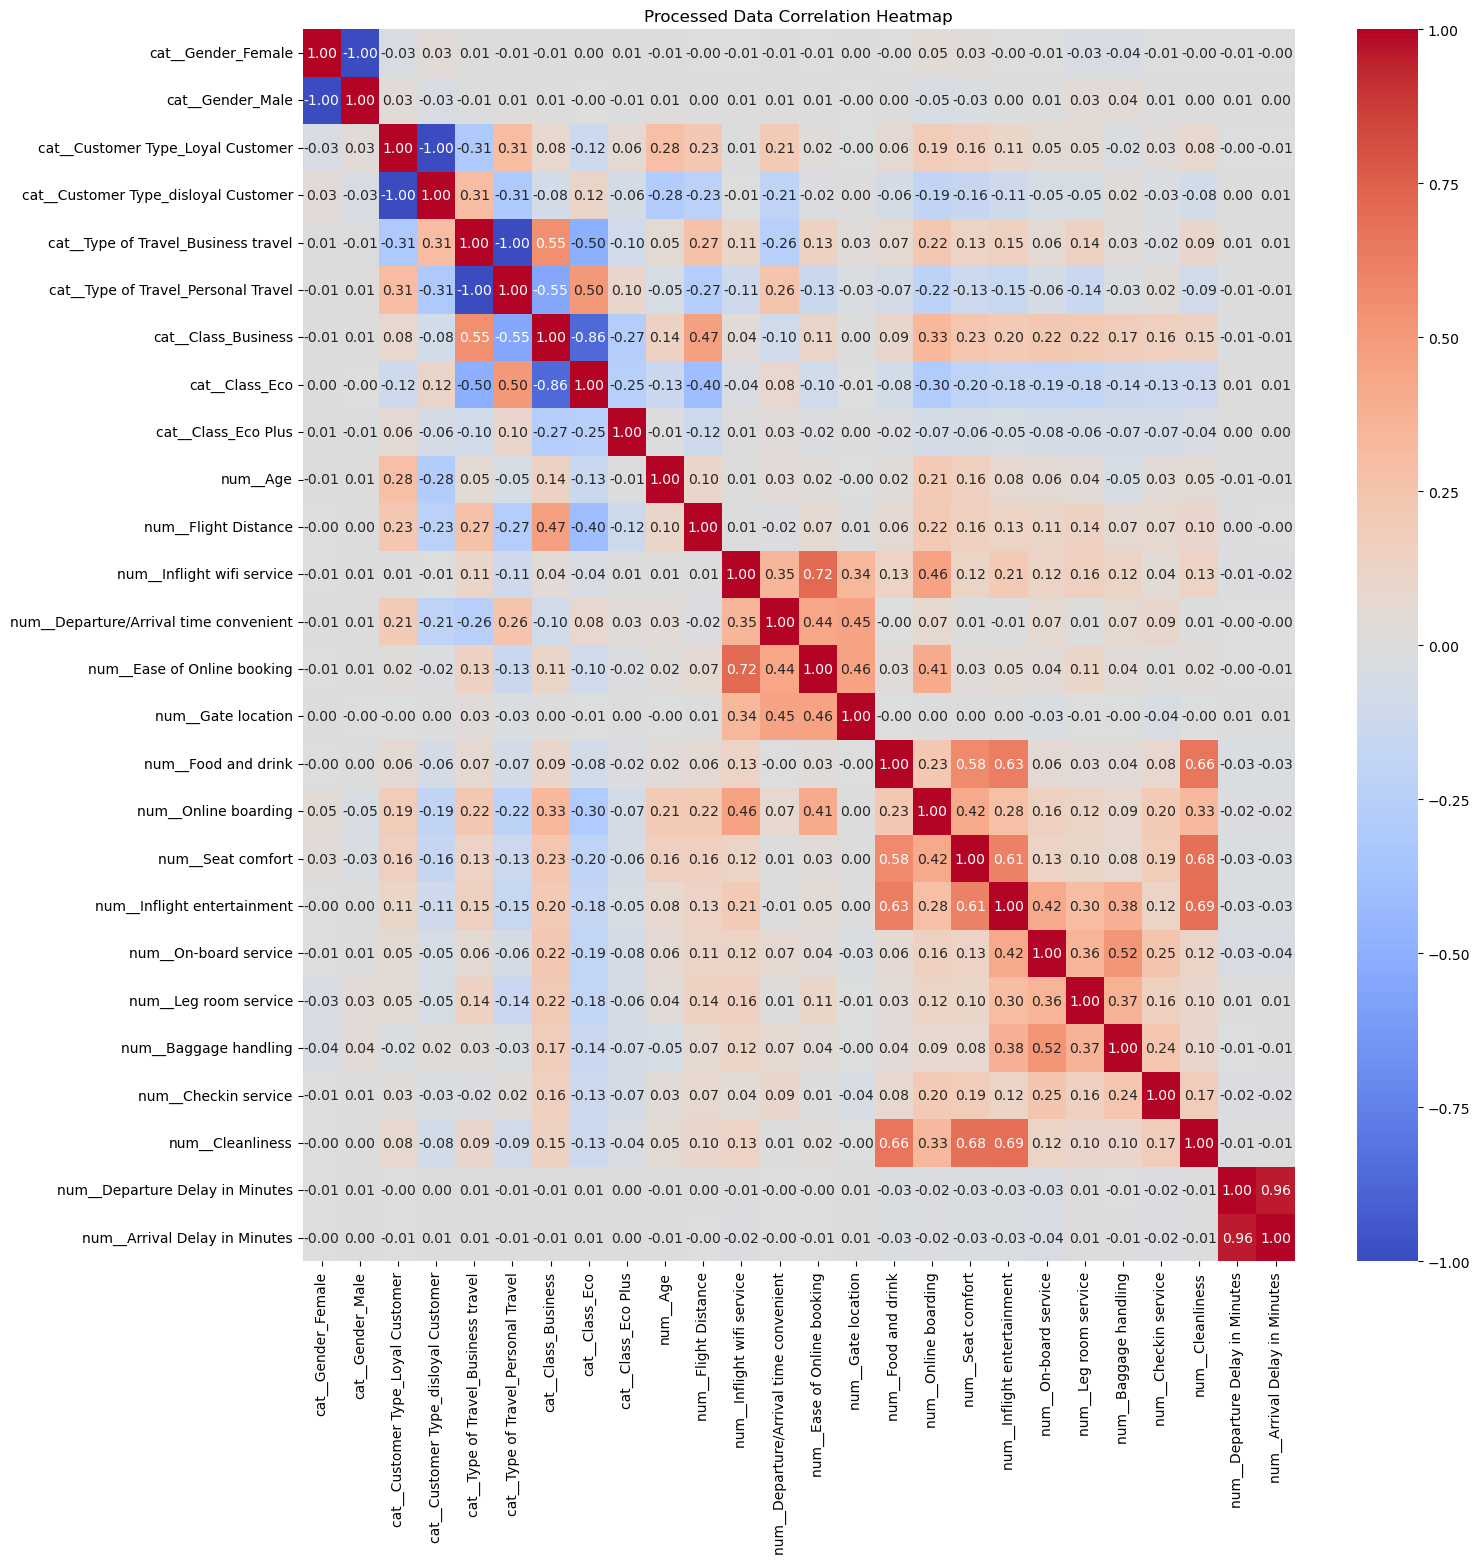

In [465]:
corr_matrix = df_processed.corr()
plt.figure(figsize=(16, 16))

# 3. Create the heatmap
# - annot=True displays the actual correlation numbers inside the squares
# - cmap='coolwarm' uses blue for negative, red for positive, and gray/white for neutral
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)

# 4. Display the plot
plt.title("Processed Data Correlation Heatmap")
plt.show()

### Model Training

In [441]:

model = LinearRegression()

In [442]:
model.fit(df_processed, output)

LinearRegression()

In [443]:
y_test = preprocessor.transform(df_test)

In [444]:
y_pred = model.predict(y_test)

In [445]:
y_test = label_encode.transform(Y_test)

### Error or accuracy calculation

In [446]:
from sklearn.metrics import mean_squared_error

In [447]:
mse = mean_squared_error(y_test, y_pred)

In [448]:
mse

0.11070198165851854

In [449]:
rmse = np.sqrt(mse)

In [450]:
rmse


np.float64(0.33271907318114263)

In [451]:
from sklearn.metrics import mean_absolute_error

In [452]:
mae = mean_absolute_error(y_test, y_pred)

In [453]:
mae

0.24914967196251464

In [454]:
from sklearn.metrics import r2_score

In [455]:
r2 = r2_score(y_test, y_pred)

In [456]:
r2

0.5500706989261313

### cross validation score

In [473]:

model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('linear_reg', LinearRegression())
])

# 2. Run 5-Fold Cross-Validation on your full training features (X_train) and targets (Y_train)
# cv=5 means the data is split into 5 chunks, running 5 separate evaluations
cv_scores = cross_val_score(model_pipeline, df, Y_train, cv=5, scoring='r2')

In [474]:
cv_scores

array([0.54840167, 0.55050438, 0.54880519, 0.55386175, 0.55495241])